# Support Vector Machines (SVMs) for Classification: A Comprehensive Guide

## Introduction to Support Vector Machines (SVMs)

Support Vector Machines (SVMs) are powerful supervised learning models used for classification and regression tasks. In classification, SVMs work by finding an optimal hyperplane that best separates data points into different classes in a high-dimensional space. The goal is to maximize the margin between the hyperplane and the nearest data points (called support vectors) from each class, which helps in better generalization to unseen data.

Key concepts in SVMs include:
- **Hyperplane:** A decision boundary that separates data points of different classes.
- **Support Vectors:** The data points that lie closest to the hyperplane. These points are crucial in defining the orientation and position of the hyperplane.
- **Margin:** The distance between the hyperplane and the support vectors. A larger margin generally indicates better generalization.
- **Kernels:** Functions that transform data into a higher-dimensional feature space, allowing for non-linear separation when the data is not linearly separable in its original space.

## Linear SVM classification

The basic idea behind the SVM classifier is to fit the widest possible street or margin between the classes. This is known as the large margin classification. Consider the figure below, there are two classes, the main goal of the SVM classifier is to the decision boundary or hyperplane that classifies the data and the support vectors with the largest margin.

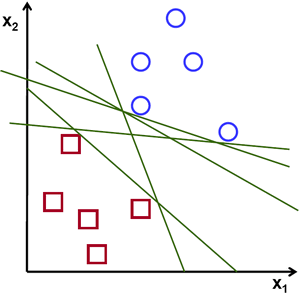

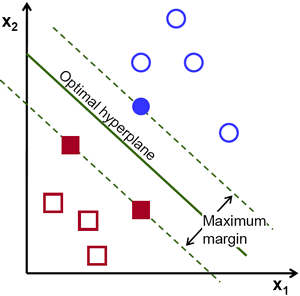

It is important to mention that SVMs classifiers are sensitive to the scale of the features. If the features are not of the same scale, this will lead to the optimization of the margin will be biased toward the largest feature. Therefore it is important to standardize your data before training the model. This can be seen in the figure below when the features have different scales, we can see that the decision boundary and the support vectors are only classifying the X1 features without taking into consideration the X0 feature, however after scaling the data to the same scale the decision boundaries and support vectors are looking much better, and the model is taking into account both features.

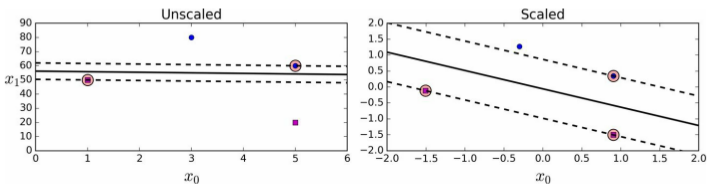


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.svm import SVC

## 1. Dataset Preparation

For this exercise, we will use the famous Iris dataset. This dataset contains 150 samples of iris flowers, each belonging to one of three species (Setosa, Versicolor, Virginica), based on four features: sepal length, sepal width, petal length, and petal width. This is a multi-class classification problem.

In [2]:
# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Convert to DataFrame for better viewing
df = pd.DataFrame(X.copy(), columns=iris.feature_names)
df['species'] = iris.target_names[y]

print("First 5 rows of the dataset:")
df.head()


First 5 rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Deliberately add missing values for imputation demonstration
np.random.seed(42)
for col in iris.feature_names:
    df.loc[df.sample(frac=0.05).index, col] = np.nan

print("\nMissing values count per column:")
print(df.isnull().sum())


Missing values count per column:
sepal length (cm)    8
sepal width (cm)     8
petal length (cm)    8
petal width (cm)     8
species              0
dtype: int64


In [4]:
# Perform Median Imputation for each feature column
for col in iris.feature_names:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after Median Imputation:")
print(df.isnull().sum())

Missing values after Median Imputation:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [5]:
print("\nTarget distribution:")
display(df['species'].value_counts())


Target distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


In [6]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"\nTraining data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")


Training data shape: (105, 4)
Testing data shape: (45, 4)


In [7]:
# Standardize the features (important for SVMs)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeatures scaled successfully.")


Features scaled successfully.


### 1.1 Initial Data Visualization

Before diving into SVMs, let's visualize the Iris dataset in 2D using Principal Component Analysis (PCA) to get an initial understanding of its structure and natural clusters.

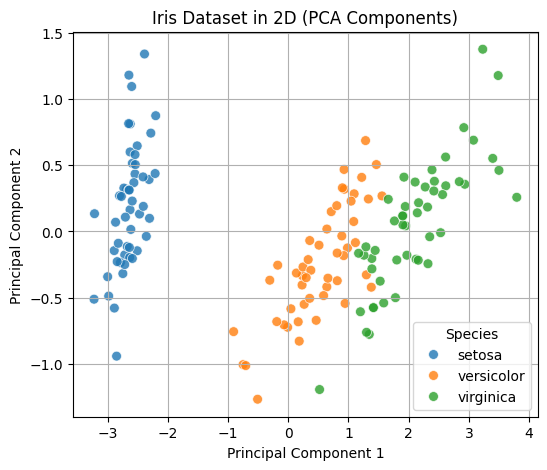

Explained variance by 2 PCA components for visualization: 0.98


In [8]:
# Visualize the original dataset using PCA for 2D representation
pca_viz = PCA(n_components=2, random_state=42)
X_pca_viz = pca_viz.fit_transform(X)

plt.figure(figsize=(6, 5))
sns.scatterplot(
    x=X_pca_viz[:, 0],
    y=X_pca_viz[:, 1],
    hue=iris.target_names[y],
    palette='tab10',
    s=50,
    alpha=0.8
)
plt.title('Iris Dataset in 2D (PCA Components)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.legend(title='Species')
plt.show()

print(f"Explained variance by 2 PCA components for visualization: {pca_viz.explained_variance_ratio_.sum():.2f}")

In [9]:
def plot_decision_boundary(model, X_plot, y_plot, title, labels=None):
    fig, ax = plt.subplots(figsize=(6, 5))

    # Define the bounds of the plot
    x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
    y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1

    # Create a mesh grid
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    # Predict across the entire mesh grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Define specific colors to match cell c08049c4 (blue, orange/yellow, green)
    # tab10 mapping: 0: blue, 1: orange, 2: green
    custom_palette = sns.color_palette("tab10", 3)

    # Plot decision regions
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.tab10)

    # Plot the original data points with mapped labels to ensure consistent coloring
    hue_labels = [labels[i] for i in y_plot] if labels is not None else y_plot

    sns.scatterplot(
        x=X_plot[:, 0],
        y=X_plot[:, 1],
        hue=hue_labels,
        palette='tab10',
        hue_order=list(labels) if labels is not None else None,
        s=60,
        edgecolor='k',
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Feature 1 (Scaled)')
    ax.set_ylabel('Feature 2 (Scaled)')
    ax.legend(loc='upper right', title='Species')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

def plot_confusion_matrix(y_true, y_pred, title, labels):
    fig, ax = plt.subplots(figsize=(6, 5))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()
    plt.show()

print("Plotting functions updated to match the original species color mapping.")

Plotting functions updated to match the original species color mapping.


## 2. Analysis with 2D Original Scaled Features

This section focuses on training and visualizing SVMs on a reduced 2-dimensional feature set (sepal length and sepal width) from the original scaled data. This allows for direct plotting of decision boundaries to understand how different kernels separate the classes in a simplified space.

In [10]:
# Prepare 2D data using only the first two features of the scaled data
X_train_2d = X_train_scaled[:, :2]
X_test_2d = X_test_scaled[:, :2]

# Dictionary to store models for 2D visualization
svm_2d_models_new = {}

print("2D data prepared using the first two original scaled features.")

2D data prepared using the first two original scaled features.


### 2.1 Linear Kernel (2D Original Scaled Features)

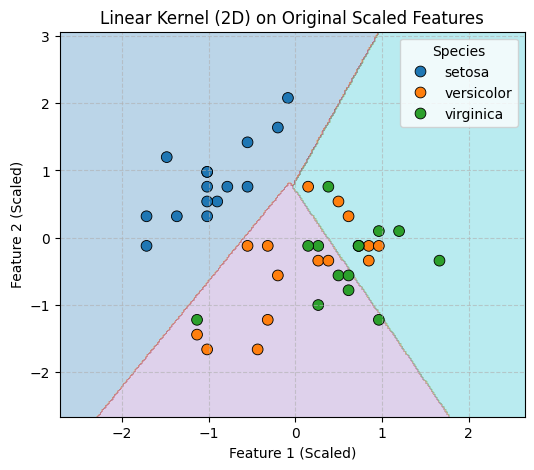

In [11]:
# --- Linear Kernel on 2D data ---
svm_2d_linear_new = SVC(kernel='linear', random_state=42)
svm_2d_linear_new.fit(X_train_2d, y_train)
svm_2d_models_new['linear'] = svm_2d_linear_new

plot_decision_boundary(svm_2d_linear_new, X_test_2d, y_test, 'Linear Kernel (2D) on Original Scaled Features', iris.target_names)

### 2.2 Polynomial Kernel (2D Original Scaled Features)

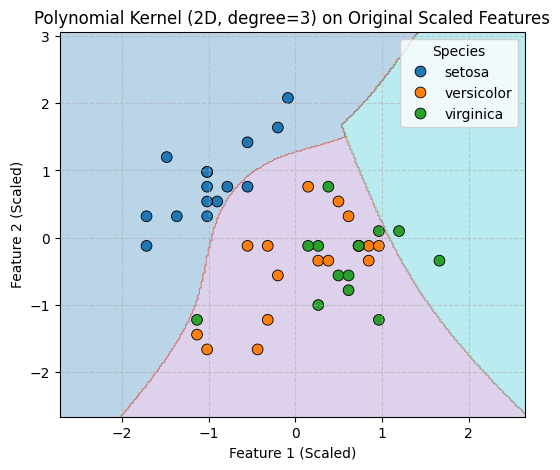

In [12]:
# --- Polynomial Kernel on 2D data ---
svm_2d_poly_new = SVC(kernel='poly', degree=3, random_state=42)
svm_2d_poly_new.fit(X_train_2d, y_train)
svm_2d_models_new['poly'] = svm_2d_poly_new

plot_decision_boundary(svm_2d_poly_new, X_test_2d, y_test, 'Polynomial Kernel (2D, degree=3) on Original Scaled Features', iris.target_names)

### 2.3 RBF Kernel (2D Original Scaled Features)

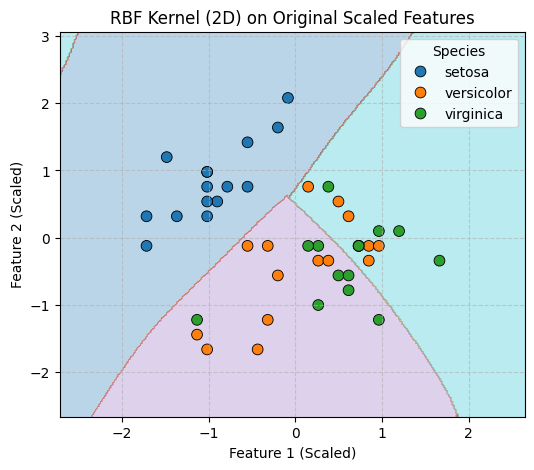

In [13]:
# --- RBF Kernel on 2D data ---
svm_2d_rbf_new = SVC(kernel='rbf', random_state=42)
svm_2d_rbf_new.fit(X_train_2d, y_train)
svm_2d_models_new['rbf'] = svm_2d_rbf_new

plot_decision_boundary(svm_2d_rbf_new, X_test_2d, y_test, 'RBF Kernel (2D) on Original Scaled Features', iris.target_names)

## 3. Analysis with Full Original Scaled Features

Here, we train SVM models with various kernel functions (Linear, Polynomial, RBF) on the complete set of original scaled features. We will then evaluate their performance using accuracy, classification reports, and confusion matrices.

In [14]:
# Dictionaries to store models, predictions, and reports for full dataset analysis
svm_models_full = {}
svm_predictions_full = {}
svm_reports_full = {}

print("Initialized dictionaries for full dataset analysis.")

Initialized dictionaries for full dataset analysis.


### 3.1 Linear Kernel (Full Original Scaled Features)

In [15]:
# --- Linear Kernel ---
svm_linear_full = SVC(kernel='linear', random_state=42)
svm_linear_full.fit(X_train_scaled, y_train)
y_pred_linear_full = svm_linear_full.predict(X_test_scaled)
svm_models_full['linear'] = svm_linear_full
svm_predictions_full['linear'] = y_pred_linear_full

print(f"Accuracy (Linear Kernel): {accuracy_score(y_test, y_pred_linear_full):.4f}")
svm_reports_full['linear'] = classification_report(y_test, y_pred_linear_full, target_names=iris.target_names, output_dict=True)
print(classification_report(y_test, y_pred_linear_full, target_names=iris.target_names))

Accuracy (Linear Kernel): 0.9111
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



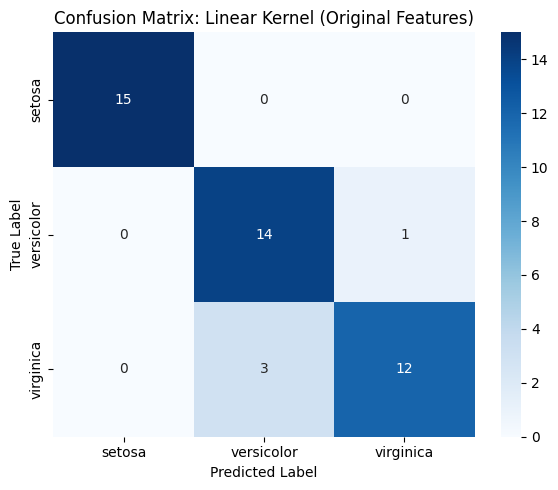

In [16]:
plot_confusion_matrix(y_test, svm_predictions_full['linear'], 'Confusion Matrix: Linear Kernel (Original Features)', iris.target_names)

### 3.2 Polynomial Kernel (Full Original Scaled Features)

In [17]:
# --- Polynomial Kernel ---
svm_poly_full = SVC(kernel='poly', degree=3, random_state=42)
svm_poly_full.fit(X_train_scaled, y_train)
y_pred_poly_full = svm_poly_full.predict(X_test_scaled)
svm_models_full['poly'] = svm_poly_full
svm_predictions_full['poly'] = y_pred_poly_full

print(f"Accuracy (Polynomial Kernel): {accuracy_score(y_test, y_pred_poly_full):.4f}")
svm_reports_full['poly'] = classification_report(y_test, y_pred_poly_full, target_names=iris.target_names, output_dict=True)
print(classification_report(y_test, y_pred_poly_full, target_names=iris.target_names))

Accuracy (Polynomial Kernel): 0.8667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.71      1.00      0.83        15
   virginica       1.00      0.60      0.75        15

    accuracy                           0.87        45
   macro avg       0.90      0.87      0.86        45
weighted avg       0.90      0.87      0.86        45



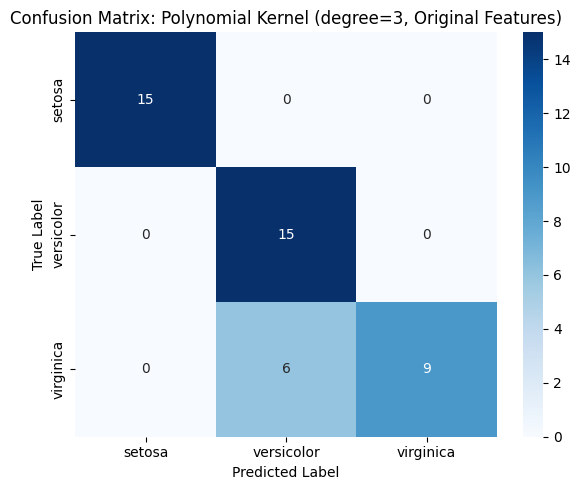

In [18]:
plot_confusion_matrix(y_test, svm_predictions_full['poly'], 'Confusion Matrix: Polynomial Kernel (degree=3, Original Features)', iris.target_names)

### 3.3 RBF Kernel (Full Original Scaled Features)

In [19]:
# --- RBF Kernel ---
svm_rbf_full = SVC(kernel='rbf', random_state=42)
svm_rbf_full.fit(X_train_scaled, y_train)
y_pred_rbf_full = svm_rbf_full.predict(X_test_scaled)
svm_models_full['rbf'] = svm_rbf_full
svm_predictions_full['rbf'] = y_pred_rbf_full

print(f"Accuracy (RBF Kernel): {accuracy_score(y_test, y_pred_rbf_full):.4f}")
svm_reports_full['rbf'] = classification_report(y_test, y_pred_rbf_full, target_names=iris.target_names, output_dict=True)
print(classification_report(y_test, y_pred_rbf_full, target_names=iris.target_names))

Accuracy (RBF Kernel): 0.9333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



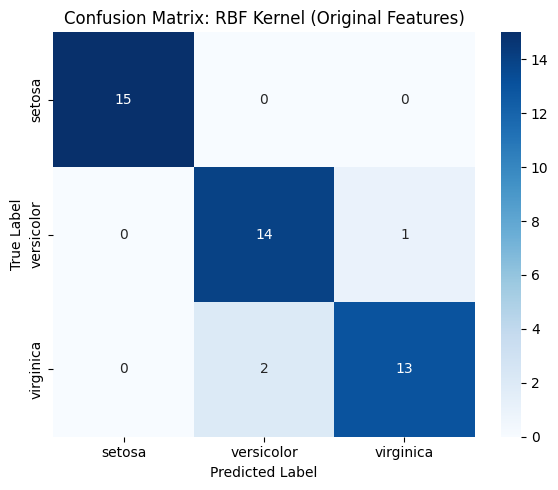

In [20]:
plot_confusion_matrix(y_test, svm_predictions_full['rbf'], 'Confusion Matrix: RBF Kernel (Original Features)', iris.target_names)

## 4. Analysis with PCA-Transformed Data

This section applies Principal Component Analysis (PCA) for dimensionality reduction and then trains SVMs with different kernels on the 2-component PCA-transformed data. We will evaluate performance and visualize decision boundaries in this reduced space.

### 4.1 PCA Transformation

In [21]:
# --- Perform PCA ---
# Reduce to 2 principal components for visualization and comparison.
pca_new = PCA(n_components=2, random_state=42)
X_train_pca_new = pca_new.fit_transform(X_train_scaled)
X_test_pca_new = pca_new.transform(X_test_scaled)

print(f"Original training data shape: {X_train_scaled.shape}")
print(f"PCA-transformed training data shape: {X_train_pca_new.shape}")
print(f"Explained variance ratio by 2 components: {pca_new.explained_variance_ratio_.sum():.4f}")

# Dictionaries to store models, predictions, and reports after PCA
svm_pca_models_new = {}
svm_pca_predictions_new = {}
svm_pca_reports_new = {}

print("PCA transformation complete and dictionaries initialized for PCA analysis.")

Original training data shape: (105, 4)
PCA-transformed training data shape: (105, 2)
Explained variance ratio by 2 components: 0.9602
PCA transformation complete and dictionaries initialized for PCA analysis.


### 4.2 Linear Kernel (PCA-Transformed Data)

In [22]:
# --- Linear Kernel with PCA ---
svm_pca_linear_new = SVC(kernel='linear', random_state=42)
svm_pca_linear_new.fit(X_train_pca_new, y_train)
y_pred_pca_linear_new = svm_pca_linear_new.predict(X_test_pca_new)
svm_pca_models_new['linear'] = svm_pca_linear_new
svm_pca_predictions_new['linear'] = y_pred_pca_linear_new

print(f"Accuracy (PCA + Linear Kernel): {accuracy_score(y_test, y_pred_pca_linear_new):.4f}")
svm_pca_reports_new['linear'] = classification_report(y_test, y_pred_pca_linear_new, target_names=iris.target_names, output_dict=True)
print(classification_report(y_test, y_pred_pca_linear_new, target_names=iris.target_names))

Accuracy (PCA + Linear Kernel): 0.9111
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



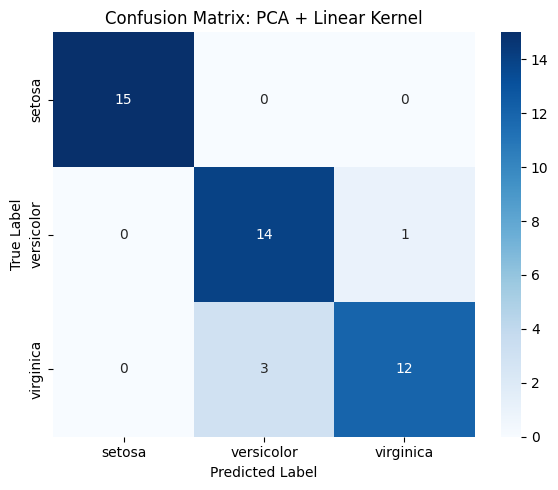

In [23]:
plot_confusion_matrix(y_test, svm_pca_predictions_new['linear'], 'Confusion Matrix: PCA + Linear Kernel', iris.target_names)

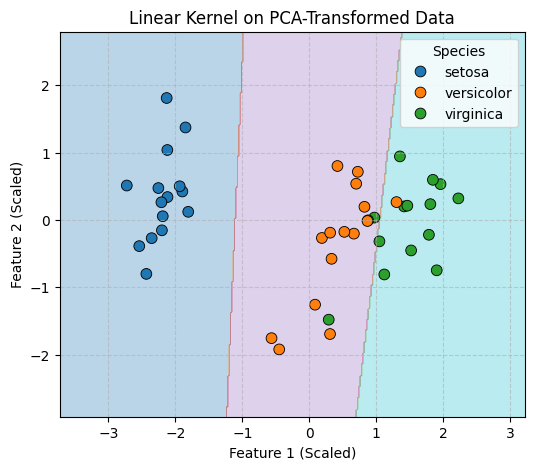

In [24]:
plot_decision_boundary(svm_pca_models_new['linear'], X_test_pca_new, y_test, 'Linear Kernel on PCA-Transformed Data', iris.target_names)

### 4.3 Polynomial Kernel (PCA-Transformed Data)

In [25]:
# --- Polynomial Kernel with PCA ---
svm_pca_poly_new = SVC(kernel='poly', degree=3, random_state=42)
svm_pca_poly_new.fit(X_train_pca_new, y_train)
y_pred_pca_poly_new = svm_pca_poly_new.predict(X_test_pca_new)
svm_pca_models_new['poly'] = svm_pca_poly_new
svm_pca_predictions_new['poly'] = y_pred_pca_poly_new

print(f"Accuracy (PCA + Polynomial Kernel): {accuracy_score(y_test, y_pred_pca_poly_new):.4f}")
svm_pca_reports_new['poly'] = classification_report(y_test, y_pred_pca_poly_new, target_names=iris.target_names, output_dict=True)
print(classification_report(y_test, y_pred_pca_poly_new, target_names=iris.target_names))

Accuracy (PCA + Polynomial Kernel): 0.8889
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.75      1.00      0.86        15
   virginica       1.00      0.67      0.80        15

    accuracy                           0.89        45
   macro avg       0.92      0.89      0.89        45
weighted avg       0.92      0.89      0.89        45



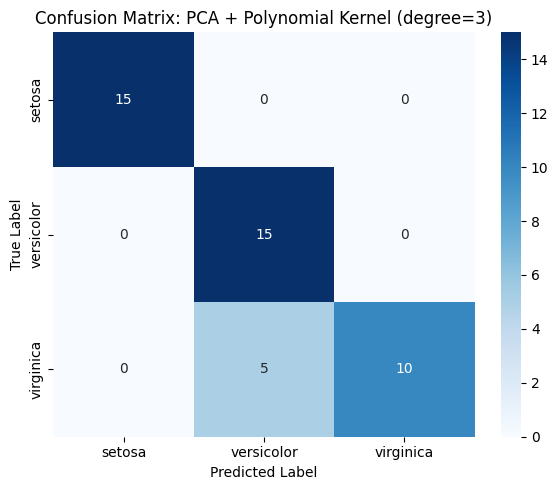

In [26]:
plot_confusion_matrix(y_test, svm_pca_predictions_new['poly'], 'Confusion Matrix: PCA + Polynomial Kernel (degree=3)', iris.target_names)

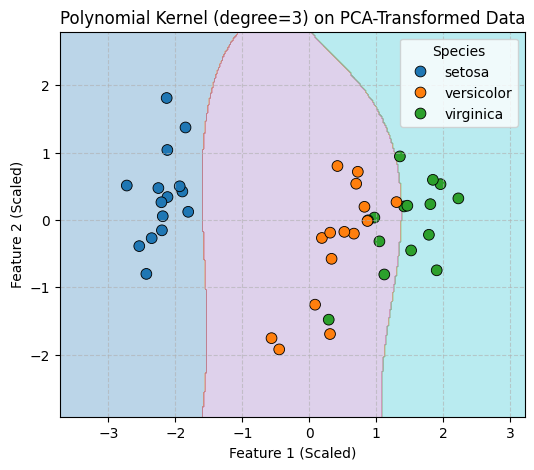

In [27]:
plot_decision_boundary(svm_pca_models_new['poly'], X_test_pca_new, y_test, 'Polynomial Kernel (degree=3) on PCA-Transformed Data', iris.target_names)

### 4.4 RBF Kernel (PCA-Transformed Data)

In [28]:
# --- RBF Kernel with PCA ---
svm_pca_rbf_new = SVC(kernel='rbf', random_state=42)
svm_pca_rbf_new.fit(X_train_pca_new, y_train)
y_pred_pca_rbf_new = svm_pca_rbf_new.predict(X_test_pca_new)
svm_pca_models_new['rbf'] = svm_pca_rbf_new
svm_pca_predictions_new['rbf'] = y_pred_pca_rbf_new

print(f"Accuracy (PCA + RBF Kernel): {accuracy_score(y_test, y_pred_pca_rbf_new):.4f}")
svm_pca_reports_new['rbf'] = classification_report(y_test, y_pred_pca_rbf_new, target_names=iris.target_names, output_dict=True)
print(classification_report(y_test, y_pred_pca_rbf_new, target_names=iris.target_names))

Accuracy (PCA + RBF Kernel): 0.9111
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



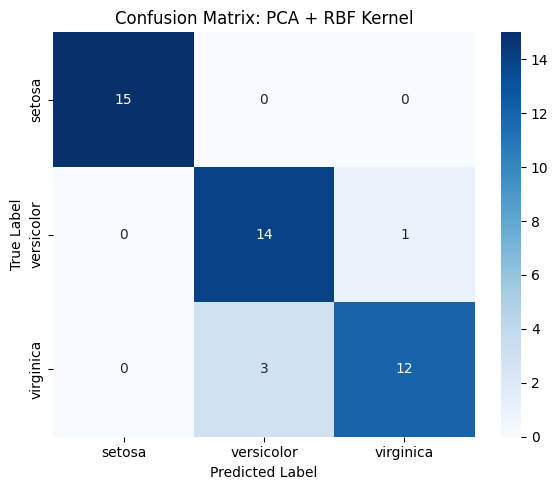

In [29]:
plot_confusion_matrix(y_test, svm_pca_predictions_new['rbf'], 'Confusion Matrix: PCA + RBF Kernel', iris.target_names)


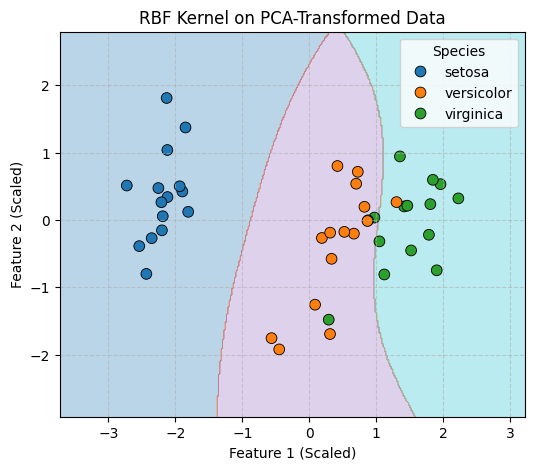

In [30]:
plot_decision_boundary(svm_pca_models_new['rbf'], X_test_pca_new, y_test, 'RBF Kernel on PCA-Transformed Data', iris.target_names)

## 5. Performance Comparison

This section provides a comparative overview of the accuracy scores achieved by all trained SVM models, both on the original scaled features and the PCA-transformed data, to highlight the impact of different kernels and dimensionality reduction.

In [31]:
# Create a dictionary to hold all accuracies for comparison
comparison_data_new = []

# Original scaled data accuracies
for kernel, report in svm_reports_full.items():
    comparison_data_new.append([f"SVM ({kernel.capitalize()} Kernel)", report['accuracy']])

# PCA-transformed data accuracies
for kernel, report in svm_pca_reports_new.items():
    comparison_data_new.append([f"SVM (PCA + {kernel.capitalize()} Kernel)", report['accuracy']])

# Convert to DataFrame for better display
comparison_df_new = pd.DataFrame(comparison_data_new, columns=['Model', 'Accuracy'])
comparison_df_new = comparison_df_new.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
comparison_df_new

,Model,Accuracy
0,SVM (Rbf Kernel),0.933333
1,SVM (Linear Kernel),0.911111
2,SVM (PCA + Rbf Kernel),0.911111
3,SVM (PCA + Linear Kernel),0.911111
4,SVM (PCA + Poly Kernel),0.888889
5,SVM (Poly Kernel),0.866667


## 6. Conclusion

In this class material, we:

-   **Prepared the Iris dataset** for classification, including splitting into training/testing sets and standardizing features.
-   **Implemented Support Vector Machines (SVMs)** using various kernel functions (linear, polynomial, RBF) on the original scaled data and compared their performance.
-   **Applied Principal Component Analysis (PCA)** for dimensionality reduction, reducing the feature space to 2 components for better visualization and understanding.
-   **Trained SVMs on the PCA-transformed data** with the same kernel functions.
-   **Evaluated and compared the classification performance** of all models, highlighting the impact of different kernels and dimensionality reduction. We observed that for the Iris dataset, the RBF kernel generally performed very well, and reducing the dimensionality with PCA (to 2 components) still allowed for high accuracy, albeit with a slight drop compared to the original features. The visualization of decision boundaries provides a clear understanding of how each kernel separates the classes in a 2D space.

This comprehensive guide provides a foundation for understanding and applying SVMs with different kernels and the role of dimensionality reduction in machine learning classification tasks.